In [306]:
%matplotlib widget

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
import polars as pl
import scipy.optimize as scio
from matplotlib import ticker

jax.config.update("jax_enable_x64", True) 
jax.config.update("jax_debug_nans", True)
cmap = 'jet'

In [307]:
data_uncoupled  = pl.read_parquet("data_complete/2026_10_21_11h44.parquet")

In [308]:
N1 = 20
N2 = 120
N3 = 190
N4 = 320
N5 = 390
N6 = 500
N7 = 600
N8 = 750

In [309]:
f_list = jnp.asarray(data_uncoupled["f"].unique())
r_list = jnp.asarray(data_uncoupled["Rload"].unique())
w_list = f_list * 2 * jnp.pi

f_list_pics = jnp.append(jnp.append(jnp.append(f_list[N1:N2], f_list[N3:N4]), f_list[N5:N6]), f_list[N7:N8])
w_list_pics = f_list_pics * 2 * jnp.pi

power1_exp = np.zeros((len(r_list),len(f_list)))
power2_exp = np.zeros((len(r_list),len(f_list)))

for i, f in enumerate(f_list):
    for j, r in enumerate(r_list): 
        df = data_uncoupled.filter((pl.col("f") == f), (pl.col("Rload") == r))
        power1_exp[j][i] = df["pow1"][0]
        power2_exp[j][i] = df["pow2"][0]

power1_exp_pics = np.zeros((len(r_list),len(f_list_pics)))
power2_exp_pics = np.zeros((len(r_list),len(f_list_pics)))

for i, f in enumerate(f_list_pics):
    for j, r in enumerate(r_list): 
        df = data_uncoupled.filter((pl.col("f") == f), (pl.col("Rload") == r))
        power1_exp_pics[j][i] = df["pow1"][0]
        power2_exp_pics[j][i] = df["pow2"][0]

In [310]:
w01 = 130 * 2 * jnp.pi
Cp1re = 5e-9
Cp1im = 5e-10
km21 = 1.1055
Q1 = 70
M1 = 5
ProtoCaracsRef1 = jnp.array([w01, Cp1re, Cp1im, km21, Q1, M1])

w02 = 97 * 2 * jnp.pi
Cp2re = 5.7781e-9
Cp2im = 5e-8
km22 = 0.35342
Q2 = 70
M2 = 5
ProtoCaracsRef2 = jnp.array([w02, Cp2re, Cp2im, km22, Q2, M2])

In [ ]:
# Fonction qui calcule la puissance


def system_signals(w, R, vect):
    """
    returns x1, x2, phi_x1, phi_x2, v1, v2, P1in, P2in
    position resonator 1, voltage resonator 1
    position resonator 2, voltage resonator 2
    computed by analytical analysis
    for the two couples linear resonators system
    """

    gamma = 0.15

    w0 = vect[0]
    Cp = vect[1]+1.j*vect[2]
    km2 = vect[3]
    Q = vect[4]
    M = vect[5]

    alpha = jnp.sqrt(km2 * M * w0**2 * Cp)
    a = -(w**2) + 1.0j * w * w0 / Q + w0**2
    b = alpha / M
    c = 1.0j * w * alpha
    d = 1.0j * w * Cp + 1 / R

    v = c * gamma / (b * c + d * a)

    P = jnp.abs(v) ** 2 / (2 * R)

    return w, R, P

In [312]:
# Calcul de la puissance en vmap sur omega et R

vpower = jax.vmap(
    jax.vmap(
        system_signals,
        in_axes=(
            0,        # omega
            None,     # R
            None,     # vect
        ),
    ),
    in_axes=(
        None,     # omega
        0,        # R
        None,       # omega
    ),
)



In [332]:
def error1_function(X0):
    caracs = X0 * ProtoCaracsRef1
    w, r, power_sim = vpower(w_list, r_list, caracs)
    return (power_sim - power1_exp).flatten()

def error2_function(X0):
    caracs = X0 * ProtoCaracsRef2
    w, r, power_sim = vpower(w_list, r_list, caracs)
    return (power_sim - power2_exp).flatten()

In [333]:
x01 = jnp.ones_like(ProtoCaracsRef1)
res1 = scio.least_squares(error1_function, x01)
xf1 = res1.x
ProtoCaracsOpt1 = xf1 * ProtoCaracsRef1

x02 = jnp.ones_like(ProtoCaracsRef2)
res2 = scio.least_squares(error2_function, x02)
xf2 = res2.x
ProtoCaracsOpt2 = xf2 * ProtoCaracsRef2


print(
    f"f01 = {ProtoCaracsOpt1[0] / (2 * jnp.pi)}, \nCp1re = {ProtoCaracsOpt1[1]}, \nCp1im = {ProtoCaracsOpt1[2]}, \nkm21 = {ProtoCaracsOpt1[3]}, \nQ1 = {ProtoCaracsOpt1[4]}, \nM1 = {ProtoCaracsOpt1[5]}"
    )


print(
    f"f02 = {ProtoCaracsOpt2[0] / (2 * jnp.pi)}, \nCp2re = {ProtoCaracsOpt2[1]}, \nCp2im = {ProtoCaracsOpt2[2]}, \nkm22 = {ProtoCaracsOpt2[3]}, \nQ2 = {ProtoCaracsOpt2[4]}, \nM2 = {ProtoCaracsOpt2[5]}"
    )

f01 = 130.60622111786284, 
Cp1re = 3.219245780706914e-09, 
Cp1im = -7.582096258596568e-10, 
km21 = 0.919216529048871, 
Q1 = 217.91892280417215, 
M1 = 0.0029156328008586346
f02 = 98.93096325643673, 
Cp2re = 2.1864168678699304e-08, 
Cp2im = -5.090365981729732e-10, 
km22 = 0.33084929264002366, 
Q2 = 52.988327304362336, 
M2 = 0.004335350235534776


In [334]:
w1_grid, r1_grid, power1_th = vpower(f_list * 2 * jnp.pi, r_list, ProtoCaracsOpt1)
f1_grid = w1_grid / (2. * jnp.pi)

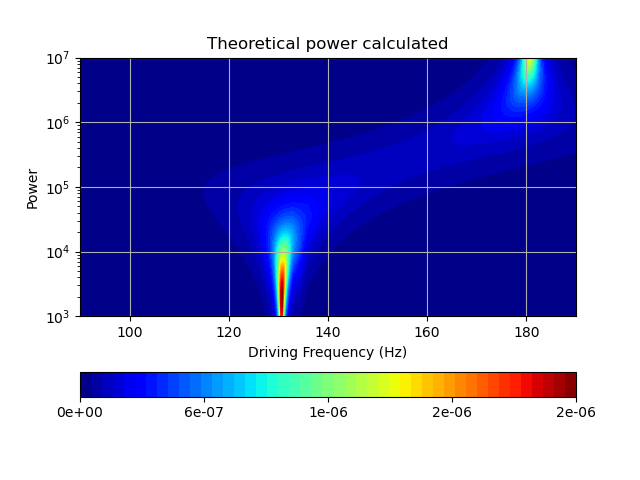

In [335]:
plt.figure()
plt.contourf(f1_grid, r1_grid, power1_th, 50, cmap=cmap)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Theoretical power calculated")
# plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

In [336]:
fig = go.Figure(data=[
    go.Surface(x=f1_grid, y=jnp.log10(r1_grid), z=power1_exp*1.e6, opacity=0.5),
    go.Surface(x=f1_grid, y=jnp.log10(r1_grid), z=power1_th*1.e6, opacity = .5, showscale=False, colorscale="jet"),

])

def update(fig):
    fig.update_layout(scene = dict(
                      xaxis=dict(
                          title=dict(
                              text='Frequency, f [Hz]'
                          )
                      ),
                      yaxis=dict(
                          title=dict(
                              text='Resistance, R [log10(Ohm)]'
                          )
                      ),
                      zaxis=dict(
                          title=dict(
                              text='Power [muW]'
                          )
                      ),
                    ),
                    width=700,
                    margin=dict(r=20, b=10, l=10, t=10))
update(fig)
fig.show()

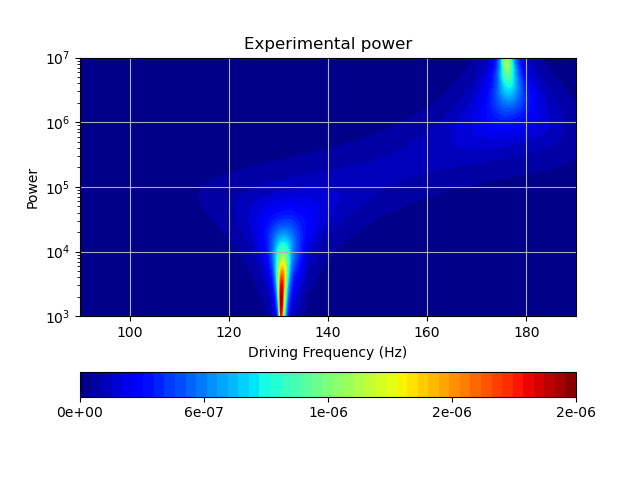

In [337]:
plt.figure()
plt.contourf(f1_grid, r1_grid, power1_exp, 50, cmap=cmap)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Experimental power")
#plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

In [338]:
fig = go.Figure(data=[
    go.Surface(x=f1_grid, y=jnp.log10(r1_grid), z=(power1_th - power1_exp)*1.e6, opacity=0.5, colorscale="jet"),

])

def update(fig):
    fig.update_layout(scene = dict(
                      xaxis=dict(
                          title=dict(
                              text='Frequency, f [Hz]'
                          )
                      ),
                      yaxis=dict(
                          title=dict(
                              text='Resistance, R [log10(Ohm)]'
                          )
                      ),
                      zaxis=dict(
                          title=dict(
                              text='Power [muW]'
                          )
                      ),
                    ),
                    width=700,
                    margin=dict(r=20, b=10, l=10, t=10))
update(fig)
fig.show()

/tmp/ipykernel_559731/1060603582.py:14: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



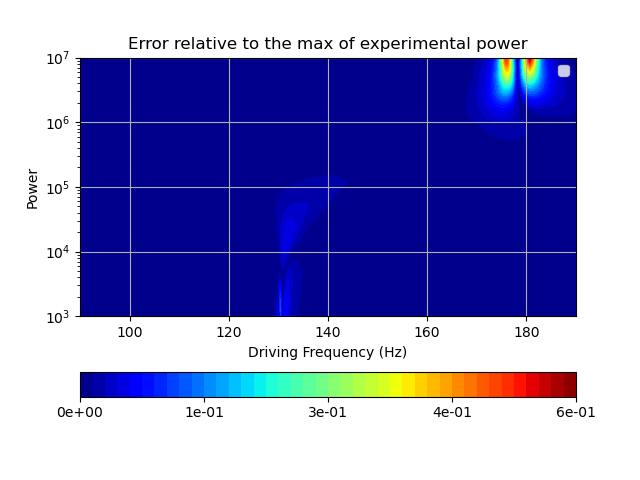

In [339]:
plt.figure()
plt.contourf(
    f_list,
    r_list,
    abs(power1_exp - power1_th) / (power1_exp.max(axis=1).max(axis=0)),
    50,
    cmap=cmap,
)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Error relative to the max of experimental power")
plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

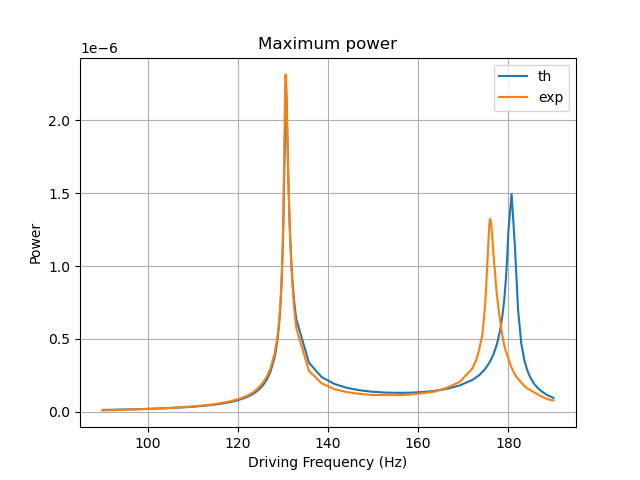

In [340]:
plt.figure()
plt.plot(f_list, power1_th.max(axis=0), label="th")
plt.plot(f_list, power1_exp.max(axis=0), label="exp")
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Maximum power")
plt.legend()
plt.grid()
plt.show()

In [341]:
w2_grid, r2_grid, power2_th = vpower(w_list, r_list, ProtoCaracsOpt2)
f2_grid = w2_grid / (2. * jnp.pi)

/tmp/ipykernel_559731/3965817321.py:8: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



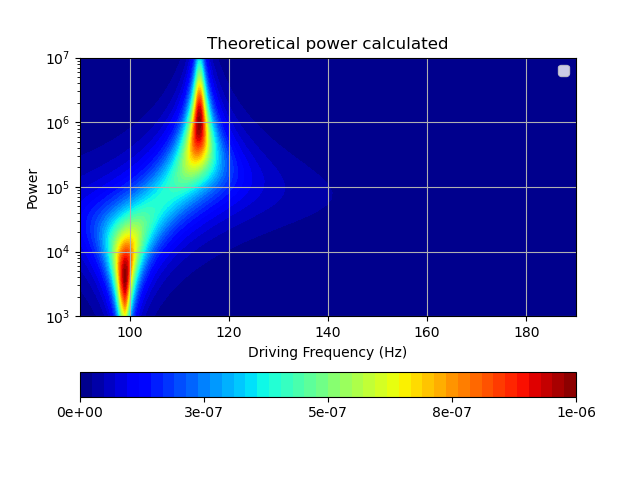

In [342]:
plt.figure()
plt.contourf(f2_grid, r2_grid, power2_th, 50, cmap=cmap)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Theoretical power calculated")
plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

In [343]:
fig = go.Figure(data=[
    go.Surface(x=f2_grid, y=jnp.log10(r2_grid), z=power2_exp*1.e6, opacity=0.5),
    go.Surface(x=f2_grid, y=jnp.log10(r2_grid), z=power2_th*1.e6, opacity = .5, showscale=False, colorscale="jet"),

])

def update(fig):
    fig.update_layout(scene = dict(
                      xaxis=dict(
                          title=dict(
                              text='Frequency, f [Hz]'
                          )
                      ),
                      yaxis=dict(
                          title=dict(
                              text='Resistance, R [log10(Ohm)]'
                          )
                      ),
                      zaxis=dict(
                          title=dict(
                              text='Power [muW]'
                          )
                      ),
                    ),
                    width=700,
                    margin=dict(r=20, b=10, l=10, t=10))
update(fig)
fig.show()

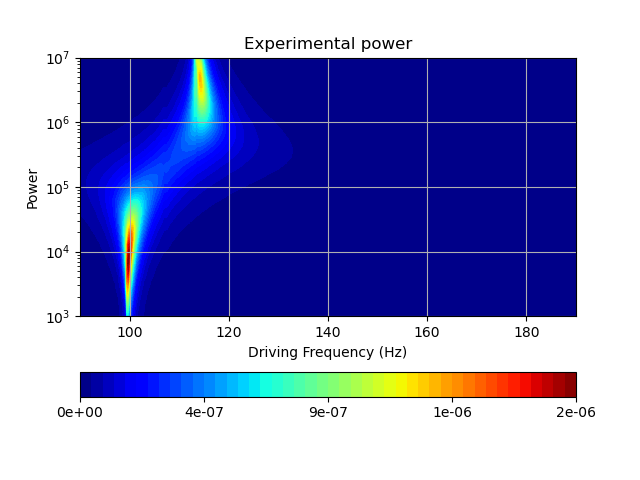

In [344]:
plt.figure()
plt.contourf(f_list, r_list, power2_exp, 50, cmap=cmap)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Experimental power")
#plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

In [345]:
fig = go.Figure(data=[
    go.Surface(x=f2_grid, y=jnp.log10(r2_grid), z=(power2_th - power2_exp)*1.e6, opacity=0.5, colorscale="jet"),

])

def update(fig):
    fig.update_layout(scene = dict(
                      xaxis=dict(
                          title=dict(
                              text='Frequency, f [Hz]'
                          )
                      ),
                      yaxis=dict(
                          title=dict(
                              text='Resistance, R [log10(Ohm)]'
                          )
                      ),
                      zaxis=dict(
                          title=dict(
                              text='Power [muW]'
                          )
                      ),
                    ),
                    width=700,
                    margin=dict(r=20, b=10, l=10, t=10))
update(fig)
fig.show()

/tmp/ipykernel_559731/2993527799.py:14: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



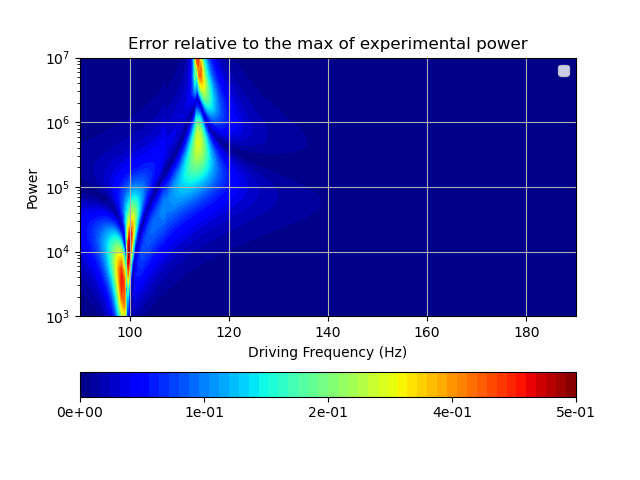

In [346]:
plt.figure()
plt.contourf(
    f_list,
    r_list,
    abs(power2_exp - power2_th) / (power2_exp.max(axis=1).max(axis=0)),
    50,
    cmap=cmap,
)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Error relative to the max of experimental power")
plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

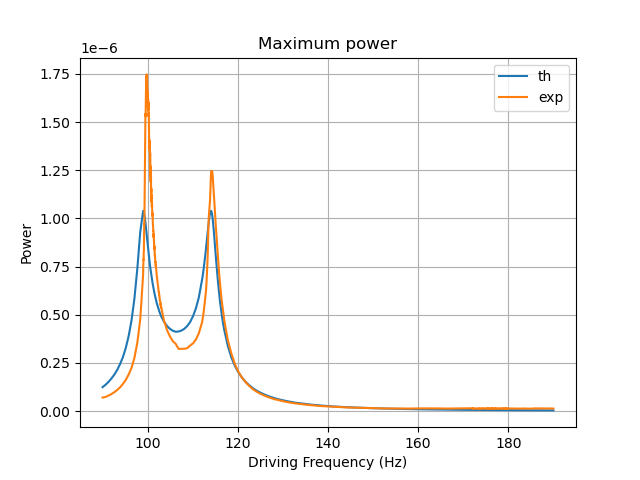

In [347]:
plt.figure()
plt.plot(f_list, power2_th.max(axis=0), label="th")
plt.plot(f_list, power2_exp.max(axis=0), label="exp")
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Maximum power")
plt.legend()
plt.grid()
plt.show()